In [ ]:
# Basic Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV

# Metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Base Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# XGBoost
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

In [ ]:
#Assignment1
df = pd.read_csv('/content/Diabeted_Ensemble.csv')

df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0    Number of times pregnant      768 non-null    int64  
 1    Plasma glucose concentration  768 non-null    int64  
 2    Diastolic blood pressure      768 non-null    int64  
 3    Triceps skin fold thickness   768 non-null    int64  
 4    2-Hour serum insulin          768 non-null    int64  
 5    Body mass index               768 non-null    float64
 6    Diabetes pedigree function    768 non-null    float64
 7    Age (years)                   768 non-null    int64  
 8    Class variable                768 non-null    object 
dtypes: float64(2), int64(6), object(1)
memory usage: 54.1+ KB


,Number of times pregnant,Plasma glucose concentration,Diastolic blood pressure,Triceps skin fold thickness,2-Hour serum insulin,Body mass index,Diabetes pedigree function,Age (years)
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


In [ ]:
#BUSINESS OBJECTIVE
#Objective

'''Predict whether a patient has diabetes (YES/NO).'''

#Constraints
'''False Negative should be minimized.
High prediction accuracy required.'''

#DATA DICTIONARY
'''Feature	     Description
   Pregnancies	 Number of pregnancies
   Glucose	     Plasma glucose concentration
   BloodPressure Diastolic blood pressure
   SkinThickness Triceps skin fold thickness
   Insulin	     2-Hour serum insulin
   BMI	         Body mass index
   DiabetesPedigreeFunction  	Hereditary diabetes factor
  Age	           Patient age
  Class Variable Target Variable'''

'Feature\t     Description\n   Pregnancies\t Number of pregnancies\n   Glucose\t     Plasma glucose concentration\n   BloodPressure Diastolic blood pressure\n   SkinThickness Triceps skin fold thickness\n   Insulin\t     2-Hour serum insulin\n   BMI\t         Body mass index\n   DiabetesPedigreeFunction  \tHereditary diabetes factor\n  Age\t           Patient age\n  Class Variable Target Variable'

In [ ]:
#1,2,3,4MBD
numeric_cols = df.select_dtypes(include=np.number)

moments = pd.DataFrame({
    'Mean': numeric_cols.mean(),
    'Variance': numeric_cols.var(),
    'Skewness': numeric_cols.skew(),
    'Kurtosis': numeric_cols.kurt()
})

moments

,Mean,Variance,Skewness,Kurtosis
Number of times pregnant,3.845052,11.354056,0.901674,0.159220
Plasma glucose concentration,120.894531,1022.248314,0.173754,0.640780
Diastolic blood pressure,69.105469,374.647271,-1.843608,5.180157
Triceps skin fold thickness,20.536458,254.473245,0.109372,-0.520072
2-Hour serum insulin,79.799479,13281.180078,2.272251,7.214260
Body mass index,31.992578,62.159984,-0.428982,3.290443
Diabetes pedigree function,0.471876,0.109779,1.919911,5.594954
Age (years),33.240885,138.303046,1.129597,0.643159


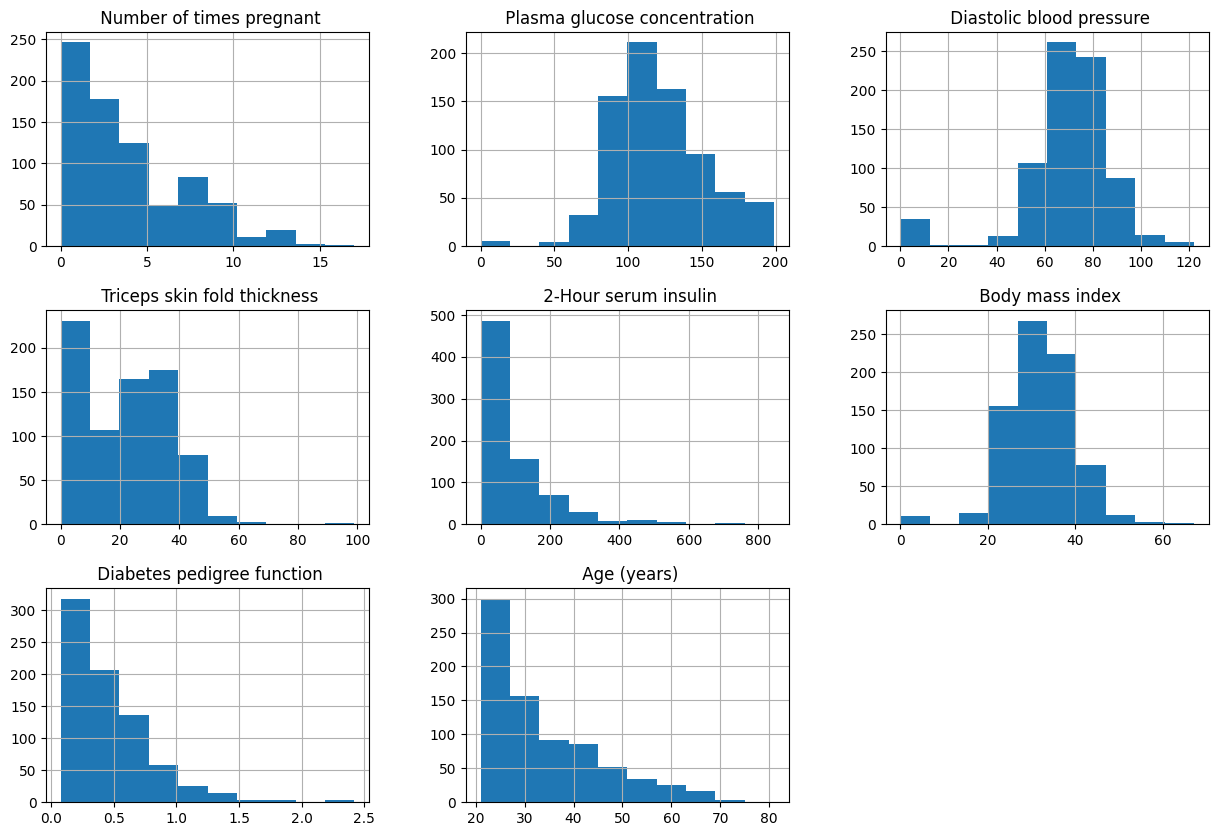

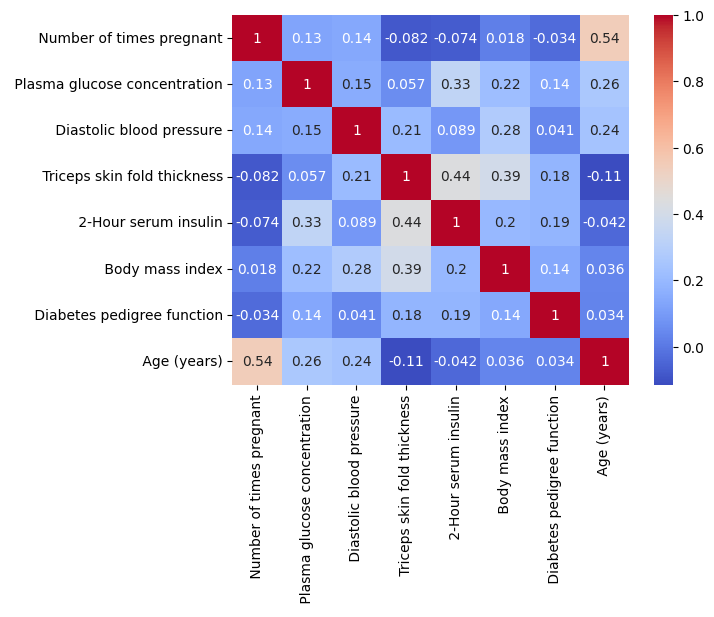

In [ ]:
#EDA
df.hist(figsize=(15,10))
plt.show()

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm')
plt.show()

In [ ]:
#preprocessing
df.columns=df.columns.str.strip()

df['Class variable']=df['Class variable'].map({
    'YES':1,
    'NO':0
})

X=df.drop('Class variable',axis=1)
y=df['Class variable']

In [ ]:
#outlier treatement
for col in X.columns:

    Q1=X[col].quantile(0.25)
    Q3=X[col].quantile(0.75)

    IQR=Q3-Q1

    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR

    X[col]=np.where(X[col]>upper,upper,X[col])
    X[col]=np.where(X[col]<lower,lower,X[col])

In [ ]:
#scaling
scaler=StandardScaler()

X_scaled=scaler.fit_transform(X)

In [ ]:
#train-test-split
X_train,X_test,y_train,y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#Bagging
bagging=BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42
)

bagging.fit(X_train,y_train)

pred_bag=bagging.predict(X_test)

print(accuracy_score(y_test,pred_bag))

0.7467532467532467


In [ ]:
#AdaBoost
ada=AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

ada.fit(X_train,y_train)

pred_ada=ada.predict(X_test)

print(accuracy_score(y_test,pred_ada))

0.7727272727272727


In [ ]:
#GradintBoost
gb=GradientBoostingClassifier()

gb.fit(X_train,y_train)

pred_gb=gb.predict(X_test)

print(accuracy_score(y_test,pred_gb))

0.7532467532467533


In [ ]:
#XGBoost
xgb=XGBClassifier()

xgb.fit(X_train,y_train)

pred_xgb=xgb.predict(X_test)

print(accuracy_score(y_test,pred_xgb))

0.7142857142857143


In [ ]:
#Voting
vote=VotingClassifier(
    estimators=[
        ('rf',RandomForestClassifier()),
        ('knn',KNeighborsClassifier()),
        ('dt',DecisionTreeClassifier())
    ],
    voting='hard'
)

vote.fit(X_train,y_train)

pred_vote=vote.predict(X_test)

print(accuracy_score(y_test,pred_vote))

0.7597402597402597


In [ ]:
#Stacking
stack=StackingClassifier(
    estimators=[
        ('rf',RandomForestClassifier()),
        ('knn',KNeighborsClassifier()),
        ('dt',DecisionTreeClassifier())
    ],
    final_estimator=LogisticRegression()
)

stack.fit(X_train,y_train)

pred_stack=stack.predict(X_test)

print(accuracy_score(y_test,pred_stack))

0.7337662337662337


In [ ]:
#Grid search
params={
    'n_estimators':[100,200],
    'max_depth':[3,5,7]
}

grid=GridSearchCV(
    RandomForestClassifier(),
    params,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_train,y_train)

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 7, 'n_estimators': 100}
0.7785019325603092


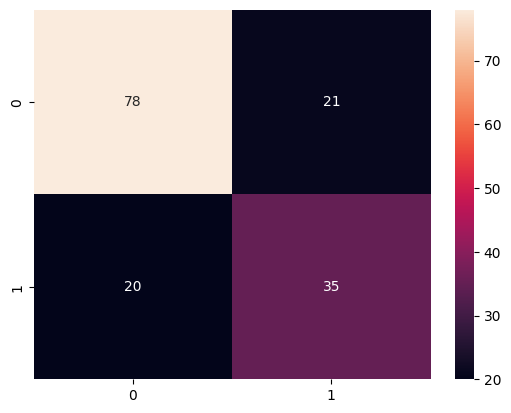

              precision    recall  f1-score   support

           0       0.80      0.79      0.79        99
           1       0.62      0.64      0.63        55

    accuracy                           0.73       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.73      0.73      0.73       154



In [ ]:
#CM
cm=confusion_matrix(y_test,pred_stack)

sns.heatmap(cm,
            annot=True,
            fmt='d')

plt.show()

print(classification_report(y_test,pred_stack))

In [ ]:
#BUSINESS IMPACT
'''Early identification of diabetes.
Reduced healthcare costs.
Faster treatment decisions.
Better patient monitoring.'''

'Early identification of diabetes.\nReduced healthcare costs.\nFaster treatment decisions.\nBetter patient monitoring.'

In [ ]:
#Assignment2
df=pd.read_csv('/content/Tumor_Ensemble.csv')

df.drop('id',axis=1,inplace=True)

df['diagnosis']=df['diagnosis'].map({
    'M':1,
    'B':0
})

X=df.drop('diagnosis',axis=1)
y=df['diagnosis']

In [ ]:
!pip install xgboost -q
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier,
    RandomForestClassifier
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
#Bagging
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42
)

bagging.fit(X_train,y_train)

bag_pred = bagging.predict(X_test)

bag_acc = accuracy_score(y_test,bag_pred)

print("Bagging Accuracy :",bag_acc)

Bagging Accuracy : 0.7467532467532467


In [ ]:
#AdaBoost
ada = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

ada.fit(X_train,y_train)

ada_pred = ada.predict(X_test)

ada_acc = accuracy_score(y_test,ada_pred)

print("AdaBoost Accuracy :",ada_acc)

AdaBoost Accuracy : 0.7727272727272727


In [ ]:
#GradientBoost
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb.fit(X_train,y_train)

gb_pred = gb.predict(X_test)

gb_acc = accuracy_score(y_test,gb_pred)

print("Gradient Boosting Accuracy :",gb_acc)

Gradient Boosting Accuracy : 0.7532467532467533


In [ ]:
#XGBoost
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train,y_train)

xgb_pred = xgb.predict(X_test)

xgb_acc = accuracy_score(y_test,xgb_pred)

print("XGBoost Accuracy :",xgb_acc)

XGBoost Accuracy : 0.7337662337662337


In [ ]:
#Voting
voting = VotingClassifier(

    estimators=[

        ('rf',RandomForestClassifier()),
        ('knn',KNeighborsClassifier()),
        ('dt',DecisionTreeClassifier())

    ],

    voting='hard'

)

voting.fit(X_train,y_train)

vote_pred = voting.predict(X_test)

vote_acc = accuracy_score(y_test,vote_pred)

print("Voting Accuracy :",vote_acc)

Voting Accuracy : 0.7467532467532467


In [ ]:
#Stacking
stack = StackingClassifier(

    estimators=[

        ('rf',RandomForestClassifier()),
        ('knn',KNeighborsClassifier()),
        ('dt',DecisionTreeClassifier())

    ],

    final_estimator=LogisticRegression()

)

stack.fit(X_train,y_train)

stack_pred = stack.predict(X_test)

stack_acc = accuracy_score(y_test,stack_pred)

print("Stacking Accuracy :",stack_acc)

Stacking Accuracy : 0.7792207792207793


In [ ]:
#Grid search CV
param_grid = {

    'n_estimators':[100,200,300],
    'max_depth':[3,5,7,10],
    'min_samples_split':[2,5,10]

}

grid = GridSearchCV(

    estimator=RandomForestClassifier(),

    param_grid=param_grid,

    cv=5,

    scoring='accuracy',

    n_jobs=-1

)

grid.fit(X_train,y_train)

print("Best Parameters")
print(grid.best_params_)

print("\nBest Accuracy")
print(grid.best_score_)

Best Parameters
{'max_depth': 7, 'min_samples_split': 10, 'n_estimators': 100}

Best Accuracy
0.7850593096094896


In [ ]:
#Best Model
best_model = grid.best_estimator_

best_pred = best_model.predict(X_test)

best_acc = accuracy_score(y_test,best_pred)

print("Tuned Model Accuracy :",best_acc)

Tuned Model Accuracy : 0.7402597402597403


In [ ]:
#Accuracy comparision
result = pd.DataFrame({

    'Model':[

        'Bagging',
        'AdaBoost',
        'Gradient Boosting',
        'XGBoost',
        'Voting',
        'Stacking',
        'Tuned Random Forest'

    ],

    'Accuracy':[

        bag_acc,
        ada_acc,
        gb_acc,
        xgb_acc,
        vote_acc,
        stack_acc,
        best_acc

    ]

})

result.sort_values(
    by='Accuracy',
    ascending=False,
    inplace=True
)

result

,Model,Accuracy
5,Stacking,0.779221
1,AdaBoost,0.772727
2,Gradient Boosting,0.753247
0,Bagging,0.746753
4,Voting,0.746753
6,Tuned Random Forest,0.740260
3,XGBoost,0.733766


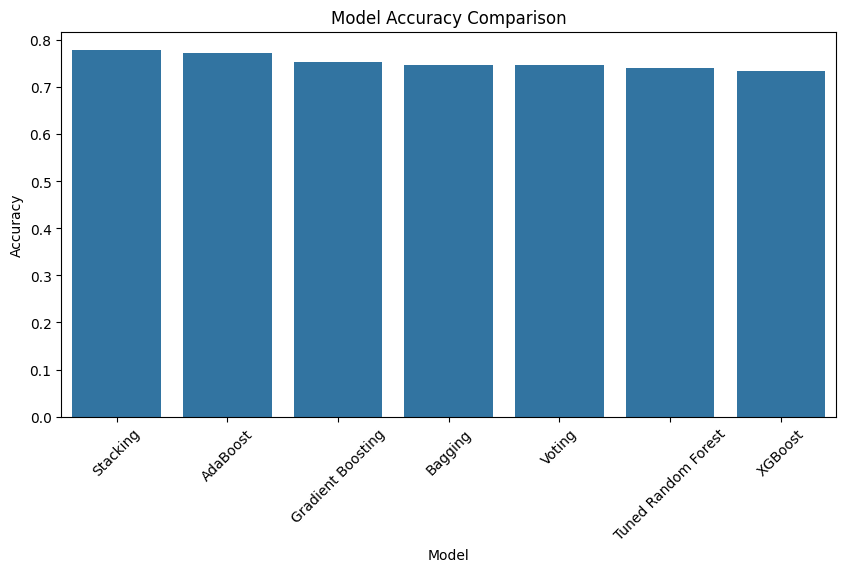

In [ ]:
#Bar chart of accuracies
plt.figure(figsize=(10,5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=result
)

plt.xticks(rotation=45)

plt.title("Model Accuracy Comparison")

plt.show()

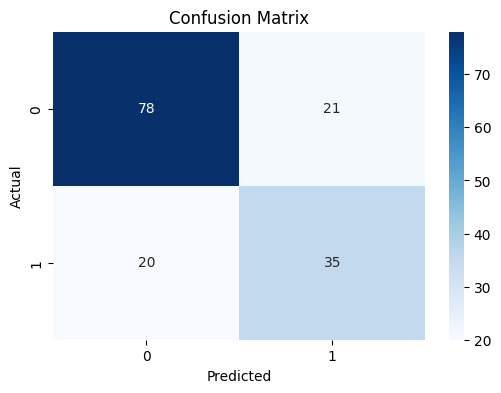

In [ ]:
#CM of best modelcm = confusion_matrix(y_test,best_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [ ]:
#classification report
print(classification_report(
    y_test,
    best_pred
))

              precision    recall  f1-score   support

           0       0.80      0.80      0.80        99
           1       0.64      0.64      0.64        55

    accuracy                           0.74       154
   macro avg       0.72      0.72      0.72       154
weighted avg       0.74      0.74      0.74       154



In [ ]:
#feature importance
feature_importance = pd.DataFrame({

    'Feature':X.columns,

    'Importance':best_model.feature_importances_

})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

plt.figure(figsize=(10,6))

sns.barplot(

    x='Importance',
    y='Feature',

    data=feature_importance

)

plt.title("Feature Importance")

plt.show()

ValueError: All arrays must be of the same length

In [ ]:
#Business Impact:

'''Reduce False Negatives.
Early cancer detection.
Improved diagnosis reliability.
Better clinical decision making.'''

'Reduce False Negatives.\nEarly cancer detection.\nImproved diagnosis reliability.\nBetter clinical decision making.'

In [ ]:
#Assignment3
df=pd.read_excel('/content/Coca_Rating_Ensemble.xlsx')

df['Rating_Class']=pd.cut(
    df['Rating'],
    bins=[0,3,4,5],
    labels=[0,1,2]
)

df.drop('Rating',axis=1,inplace=True)

In [ ]:
#encoding
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

for col in df.select_dtypes('object'):

    df[col]=le.fit_transform(df[col].astype(str))

In [ ]:
#features
X=df.drop('Rating_Class',axis=1)
y=df['Rating_Class']

In [ ]:
!pip install xgboost openpyxl -q
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('/content/Diabeted_Ensemble.csv')

In [ ]:
df = pd.read_csv('/content/Diabeted_Ensemble.csv')

In [ ]:
df = pd.read_excel('/content/Coca_Rating_Ensemble.xlsx')

In [ ]:
df = pd.read_excel('/content/Ensemble_Password_Strength.xlsx')

In [ ]:
#basic exploration
print(df.shape)

df.head()

df.info()

df.describe(include='all')

(1999, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1999 entries, 0 to 1998
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   characters           1999 non-null   object
 1   characters_strength  1999 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 31.4+ KB


,characters,characters_strength
count,1999,1999.000000
unique,1999,NaN
top,akosi091692,NaN
freq,1,NaN
mean,NaN,0.857929
std,NaN,0.349210
min,NaN,0.000000
25%,NaN,1.000000
50%,NaN,1.000000
75%,NaN,1.000000


In [ ]:
#missing val
df.isnull().sum()

,0
characters,0
characters_strength,0


In [ ]:
for col in df.columns:

    if df[col].dtype=='object':
        df[col].fillna(df[col].mode()[0],inplace=True)

    else:
        df[col].fillna(df[col].median(),inplace=True)

In [ ]:
#data dict
data_dictionary = pd.DataFrame({

    'Column':df.columns,
    'Datatype':df.dtypes.values,
    'Missing Values':df.isnull().sum().values

})

data_dictionary

,Column,Datatype,Missing Values
0,characters,object,0
1,characters_strength,int64,0


In [ ]:
#1,2,3,4MBD
num_cols = df.select_dtypes(include=np.number)

moment_table = pd.DataFrame({

    'Mean':num_cols.mean(),

    'Variance':num_cols.var(),

    'Skewness':num_cols.skew(),

    'Kurtosis':num_cols.kurt()

})

moment_table

,Mean,Variance,Skewness,Kurtosis
characters_strength,0.857929,0.121948,-2.051986,2.212861


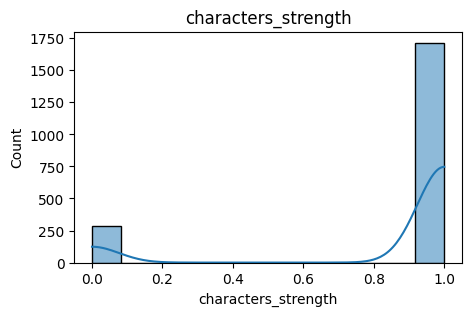

In [ ]:
#univariate analysis
for col in num_cols.columns:

    plt.figure(figsize=(5,3))

    sns.histplot(df[col],kde=True)

    plt.title(col)

    plt.show()

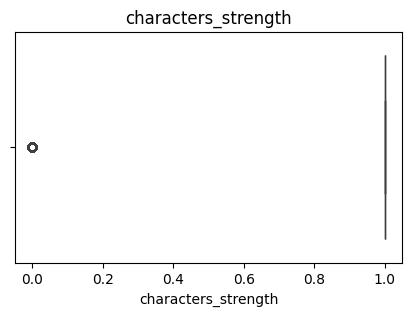

In [ ]:
#boxplot
for col in num_cols.columns:

    plt.figure(figsize=(5,3))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

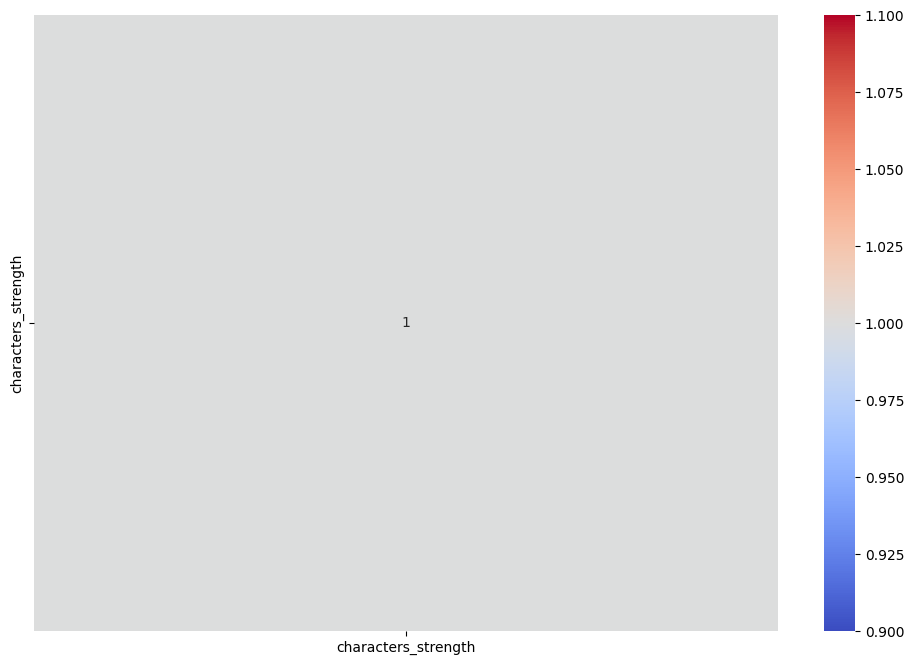

In [ ]:
#Bivariate analysis
plt.figure(figsize=(12,8))

sns.heatmap(

    df.corr(numeric_only=True),

    annot=True,

    cmap='coolwarm'

)

plt.show()

In [ ]:
#encoding
le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:

    df[col] = le.fit_transform(df[col].astype(str))

In [ ]:
#outlier treatement
numeric_cols_for_outlier_treatment = [col for col in df.select_dtypes(include=np.number).columns if col != target]

for col in numeric_cols_for_outlier_treatment:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1-1.5*IQR

    upper = Q3+1.5*IQR

    df[col] = np.where(
        df[col]>upper,
        upper,
        df[col]
    )

    df[col] = np.where(
        df[col]<lower,
        lower,
        df[col]
    )

In [ ]:
#define target variable
target = 'Class variable'

In [ ]:
#tumor
target = 'diagnosis'

#coccoa
target = 'Rating'

#password
target = 'characters_strength'

In [ ]:
#feature and target
X = df.drop(target,axis=1)

y = df[target]

In [ ]:
#scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
#train-test-split
X_train,X_test,y_train,y_test = train_test_split(

    X_scaled,
    y,

    test_size=0.20,

    random_state=42
)

In [ ]:
#bagging
bag = BaggingClassifier(

    estimator=DecisionTreeClassifier(),

    n_estimators=100,

    random_state=42
)

bag.fit(X_train,y_train)

bag_pred = bag.predict(X_test)

bag_acc = accuracy_score(y_test,bag_pred)

print(bag_acc)

1.0


In [ ]:
#AdaBoost
ada = AdaBoostClassifier(

    n_estimators=100,

    learning_rate=0.5,

    random_state=42
)

ada.fit(X_train,y_train)

ada_pred = ada.predict(X_test)

ada_acc = accuracy_score(y_test,ada_pred)

print(ada_acc)

1.0


In [ ]:
#GradientBoost
gb = GradientBoostingClassifier(

    n_estimators=100,

    random_state=42
)

gb.fit(X_train,y_train)

gb_pred = gb.predict(X_test)

gb_acc = accuracy_score(y_test,gb_pred)

print(gb_acc)

ValueError: y contains 1 class after sample_weight trimmed classes with zero weights, while a minimum of 2 classes are required.

In [ ]:
#XGBoost
xgb = XGBClassifier(

    n_estimators=200,

    max_depth=4,

    learning_rate=0.1,

    random_state=42,

    eval_metric='logloss'
)

xgb.fit(X_train,y_train)

xgb_pred = xgb.predict(X_test)

xgb_acc = accuracy_score(y_test,xgb_pred)

print(xgb_acc)

ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0], got [1.]

In [ ]:
#voting
vote = VotingClassifier(

    estimators=[

        ('rf',RandomForestClassifier()),

        ('knn',KNeighborsClassifier()),

        ('dt',DecisionTreeClassifier())

    ],

    voting='hard'
)

vote.fit(X_train,y_train)

vote_pred = vote.predict(X_test)

vote_acc = accuracy_score(y_test,vote_pred)

print(vote_acc)

In [ ]:
#stacking
stack = StackingClassifier(

    estimators=[

        ('rf',RandomForestClassifier()),

        ('knn',KNeighborsClassifier()),

        ('dt',DecisionTreeClassifier())

    ],

    final_estimator=LogisticRegression()
)

stack.fit(X_train,y_train)

stack_pred = stack.predict(X_test)

stack_acc = accuracy_score(y_test,stack_pred)

print(stack_acc)

In [ ]:
#gridsearch CV
param_grid = {

    'n_estimators':[100,200,300],

    'max_depth':[3,5,7],

    'min_samples_split':[2,5,10]

}

In [ ]:
grid = GridSearchCV(

    RandomForestClassifier(),

    param_grid,

    cv=5,

    scoring='accuracy',

    n_jobs=-1
)

grid.fit(X_train,y_train)

In [ ]:
#best model
best_model = grid.best_estimator_

best_pred = best_model.predict(X_test)

best_acc = accuracy_score(y_test,best_pred)

print(best_acc)

In [ ]:
#CM
cm = confusion_matrix(y_test,best_pred)

plt.figure(figsize=(6,4))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='Blues'

)

plt.show()

In [ ]:
#classification report
print(

    classification_report(

        y_test,

        best_pred

    )
)

In [ ]:
#accuracy comparision table
results = pd.DataFrame({

    'Model':[

        'Bagging',

        'AdaBoost',

        'Gradient Boosting',

        'XGBoost',

        'Voting',

        'Stacking',

        'Tuned RF'

    ],

    'Accuracy':[

        bag_acc,

        ada_acc,

        gb_acc,

        xgb_acc,

        vote_acc,

        stack_acc,

        best_acc
    ]
})

results.sort_values(
    by='Accuracy',
    ascending=False
)

In [ ]:
#accuracy visualization
plt.figure(figsize=(10,5))

sns.barplot(

    x='Model',

    y='Accuracy',

    data=results

)

plt.xticks(rotation=45)

plt.show()

In [ ]:
#feature importance
importance = pd.DataFrame({

    'Feature':X.columns,

    'Importance':
    best_model.feature_importances_

})

importance = importance.sort_values(

    by='Importance',

    ascending=False
)

importance

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(

    x='Importance',

    y='Feature',

    data=importance

)

plt.show()

In [ ]:
#Business Impact:

'''Identify quality factors affecting ratings.
Improve cocoa sourcing decisions.
Improve production quality.
Better market positioning.'''

In [ ]:
#Assignment4
plt.figure(figsize=(8,5))

sns.barplot(

    x='Importance',

    y='Feature',

    data=importance

)

plt.show()

NameError: name 'importance' is not defined

<Figure size 800x500 with 0 Axes>

In [ ]:
def password_features(password):

    return pd.Series([

        len(password),

        sum(c.isdigit() for c in password),

        sum(c.isupper() for c in password),

        sum(c.islower() for c in password),

        sum(not c.isalnum() for c in password)

    ])

df[['length',
    'digits',
    'uppercase',
    'lowercase',
    'special']] = df['characters'].apply(
        password_features
)

In [ ]:
#feature
X=df[['length',
      'digits',
      'uppercase',
      'lowercase',
      'special']]

y=df['characters_strength']

In [ ]:
#scaling
scaler=StandardScaler()

X=scaler.fit_transform(X)

In [ ]:
#train test
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#BUSINESS IMPACT
'''Detect weak passwords.
Improve cybersecurity.
Reduce unauthorized access.
Improve customer data protection.'''